# Tugas Praktikum 2: Praproses Data
**Nama:** Rafa Rizki Aira Swala 
**NRP:** 50425017
**Dataset:** House Prices - Advanced Regression Techniques (Kaggle)



In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

# Setting tampilan
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

In [8]:
df = pd.read_csv('train.csv')

print("Shape dataset:", df.shape)
print("\n5 Baris Pertama:")
df.head()

Shape dataset: (1460, 81)

5 Baris Pertama:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [10]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## 2. Pembersihan Data

### 2.1 Cek Nilai Hilang

In [11]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    'Jumlah Missing': missing,
    'Persentase (%)': missing_percent
})
missing_df = missing_df[missing_df['Jumlah Missing'] > 0].sort_values(
    by='Persentase (%)', ascending=False
)
print(f"Jumlah kolom dengan missing: {len(missing_df)}")
missing_df

Jumlah kolom dengan missing: 19


,Jumlah Missing,Persentase (%)
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


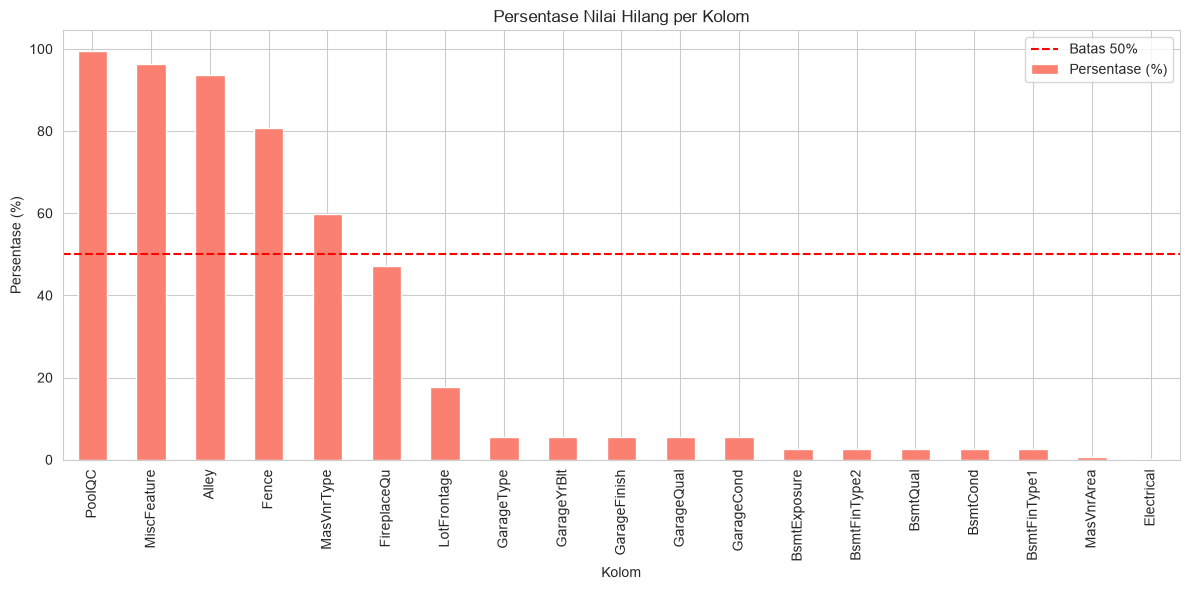

In [12]:
plt.figure(figsize=(12, 6))
missing_df['Persentase (%)'].plot(kind='bar', color='salmon')
plt.title('Persentase Nilai Hilang per Kolom')
plt.ylabel('Persentase (%)')
plt.xlabel('Kolom')
plt.axhline(y=50, color='red', linestyle='--', label='Batas 50%')
plt.legend()
plt.tight_layout()
plt.show()

### 2.2 Hapus Kolom dengan Missing > 50%


In [13]:
cols_to_drop = missing_df[missing_df['Persentase (%)'] > 50].index.tolist()
print(f"Kolom dihapus ({len(cols_to_drop)}):")
print(cols_to_drop)

df.drop(columns=cols_to_drop, inplace=True)
print("\nShape setelah hapus kolom:", df.shape)

Kolom dihapus (5):
['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']

Shape setelah hapus kolom: (1460, 76)


### 2.3 Penanganan Nilai Hilang
- Numerik → diisi dengan median 
- Kategorikal → diisi dengan modus 

In [14]:
# Pisahkan kolom numerik & kategorikal
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

# Imputasi numerik dengan median
imputer_num = SimpleImputer(strategy='median')
df[num_cols] = imputer_num.fit_transform(df[num_cols])

# Imputasi kategorikal dengan modus
imputer_cat = SimpleImputer(strategy='most_frequent')
df[cat_cols] = imputer_cat.fit_transform(df[cat_cols])

print("Total missing setelah imputasi:", df.isnull().sum().sum())

C:\Users\airal\AppData\Local\Temp\ipykernel_2476\500522249.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


Total missing setelah imputasi: 0


## 3. Deteksi dan Penanganan Outlier

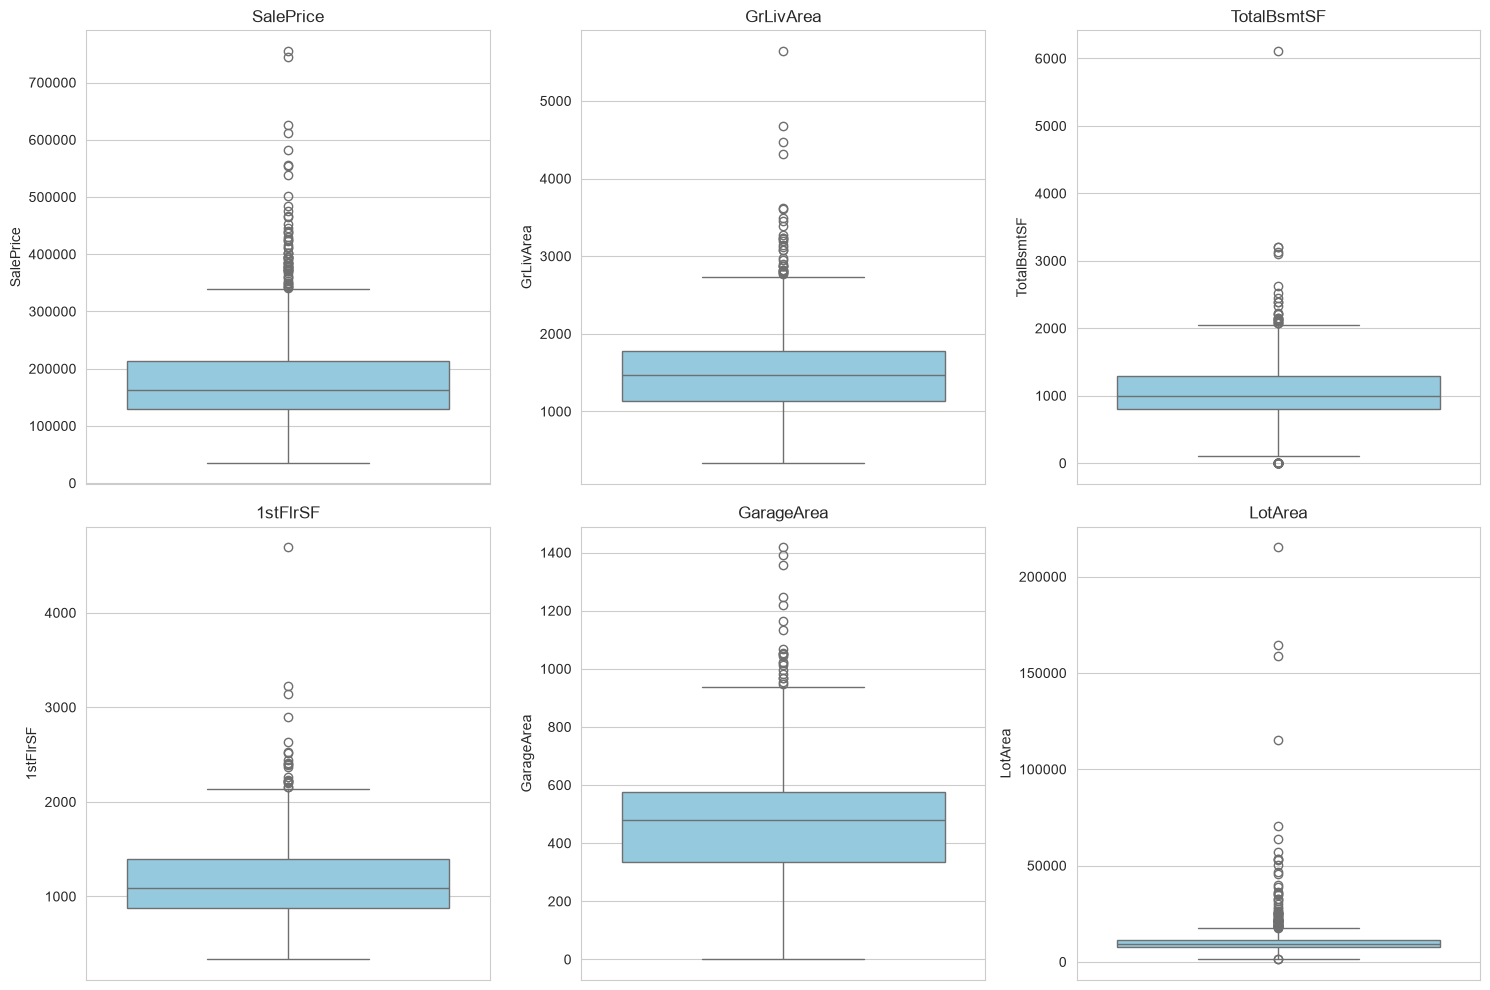

In [15]:
important_num = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'GarageArea', 'LotArea']

plt.figure(figsize=(15, 10))
for i, col in enumerate(important_num, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(col)
plt.tight_layout()
plt.show()

### Penanganan Outlier
Outlier ditangani dengan metode **IQR (Interquartile Range)**.  
Outlier dihapus pada `SalePrice` dan `GrLivArea` karena keduanya sangat memengaruhi model regresi.

In [16]:
def remove_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    before = len(data)
    data = data[(data[col] >= lower) & (data[col] <= upper)]
    print(f"{col}: {before - len(data)} outlier dihapus")
    return data

df = remove_outliers_iqr(df, 'SalePrice')
df = remove_outliers_iqr(df, 'GrLivArea')

print("\nShape setelah outlier removal:", df.shape)

SalePrice: 61 outlier dihapus
GrLivArea: 21 outlier dihapus

Shape setelah outlier removal: (1378, 76)


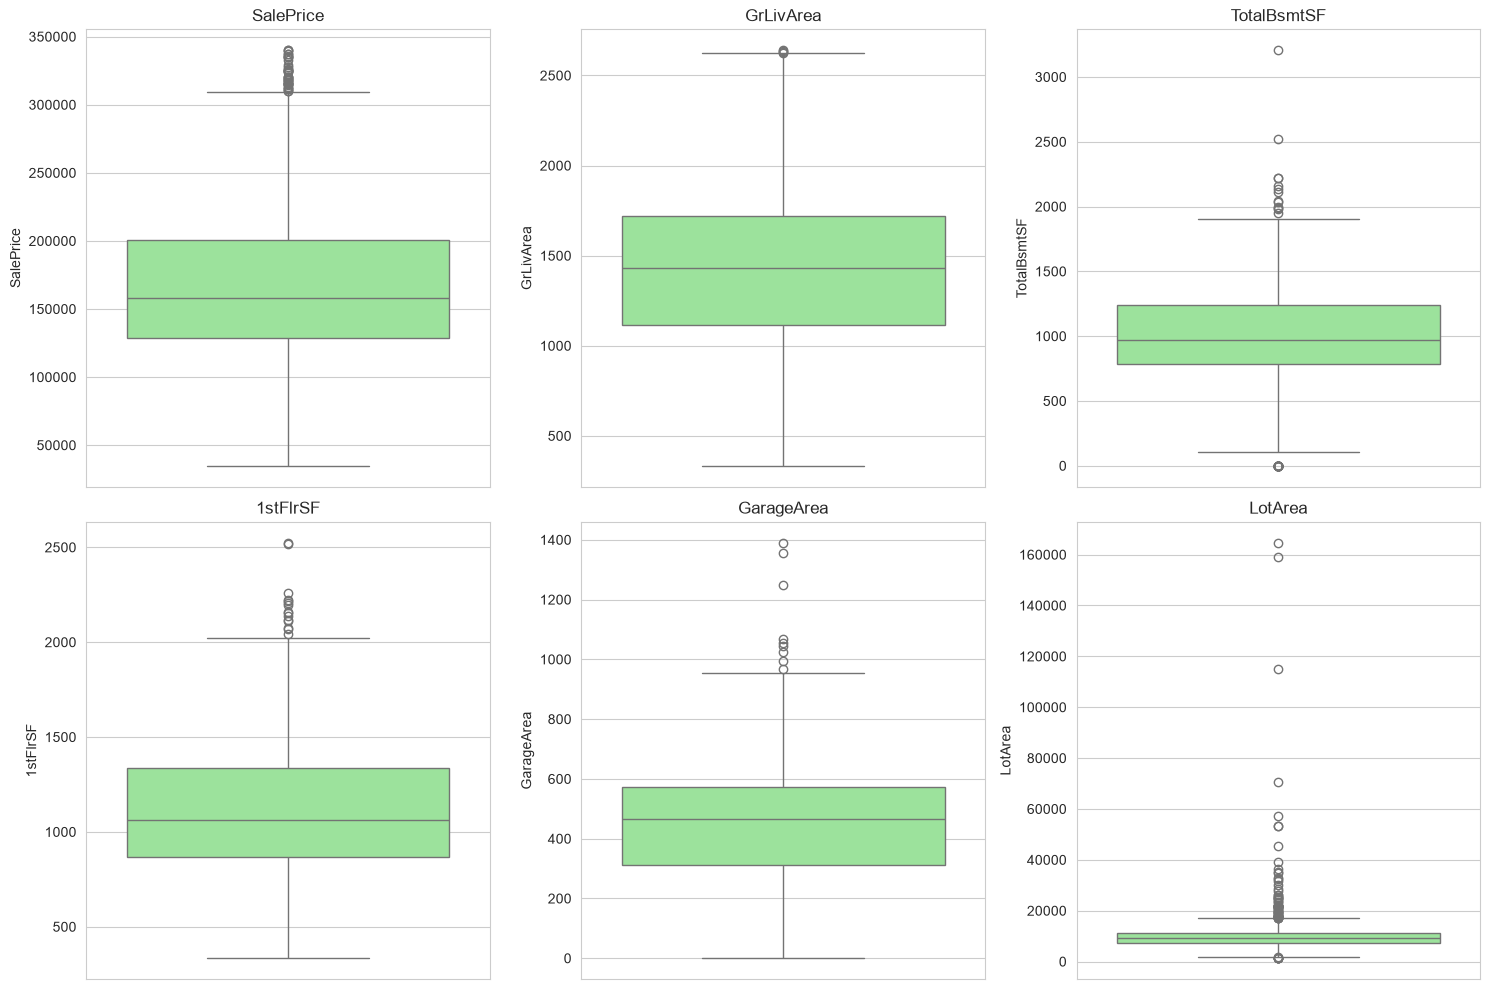

In [17]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(important_num, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='lightgreen')
    plt.title(col)
plt.tight_layout()
plt.show()

## 4. Transformasi Data

### 4.1 One-Hot Encoding
Kolom kategorikal diubah menjadi numerik menggunakan **one-hot encoding**.

In [18]:
# Pisahkan fitur & target
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

print("Shape X sebelum encoding:", X.shape)

# One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)
print("Shape X setelah encoding:", X.shape)

Shape X sebelum encoding: (1378, 75)
Shape X setelah encoding: (1378, 231)


### 4.2 Standarisasi
Atribut numerik distandarisasi menggunakan **StandardScaler** (mean=0, std=1) agar skala antar fitur seragam.

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Shape setelah scaling:", X_scaled_df.shape)
X_scaled_df.head()

Shape setelah scaling: (1378, 231)


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Pave,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_HLS,LandContour_Low,LandContour_Lvl,Utilities_NoSeWa,LotConfig_CulDSac,LotConfig_FR2,LotConfig_FR3,LotConfig_Inside,LandSlope_Mod,LandSlope_Sev,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,Condition1_Feedr,Condition1_Norm,Condition1_PosA,Condition1_PosN,Condition1_RRAe,Condition1_RRAn,Condition1_RRNe,Condition1_RRNn,Condition2_Feedr,Condition2_Norm,Condition2_RRAe,Condition2_RRAn,Condition2_RRNn,BldgType_2fmCon,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,RoofStyle_Gable,RoofStyle_Gambrel,RoofStyle_Hip,RoofStyle_Mansard,RoofStyle_Shed,RoofMatl_Membran,RoofMatl_Metal,RoofMatl_Roll,RoofMatl_Tar&Grv,RoofMatl_WdShake,RoofMatl_WdShngl,Exterior1st_AsphShn,Exterior1st_BrkComm,Exterior1st_BrkFace,Exterior1st_CBlock,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing,Exterior2nd_AsphShn,Exterior2nd_Brk Cmn,Exterior2nd_BrkFace,Exterior2nd_CBlock,Exterior2nd_CmentBd,Exterior2nd_HdBoard,Exterior2nd_ImStucc,Exterior2nd_MetalSd,Exterior2nd_Other,Exterior2nd_Plywood,Exterior2nd_Stone,Exterior2nd_Stucco,Exterior2nd_VinylSd,Exterior2nd_Wd Sdng,Exterior2nd_Wd Shng,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,ExterCond_Fa,ExterCond_Gd,ExterCond_Po,ExterCond_TA,Foundation_CBlock,Foundation_PConc,Foundation_Slab,Foundation_Stone,Foundation_Wood,BsmtQual_Fa,BsmtQual_Gd,BsmtQual_TA,BsmtCond_Gd,BsmtCond_Po,BsmtCond_TA,BsmtExposure_Gd,BsmtExposure_Mn,BsmtExposure_No,BsmtFinType1_BLQ,BsmtFinType1_GLQ,BsmtFinType1_LwQ,BsmtFinType1_Rec,BsmtFinType1_Unf,BsmtFinType2_BLQ,BsmtFinType2_GLQ,BsmtFinType2_LwQ,BsmtFinType2_Rec,BsmtFinType2_Unf,Heating_GasA,Heating_GasW,Heating_Grav,Heating_OthW,Heating_Wall,HeatingQC_Fa,HeatingQC_Gd,HeatingQC_Po,HeatingQC_TA,CentralAir_Y,Electrical_FuseF,Electrical_FuseP,Electrical_Mix,Electrical_SBrkr,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA,Functional_Maj2,Functional_Min1,Functional_Min2,Functional_Mod,Functional_Sev,Functional_Typ,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_Po,FireplaceQu_TA,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,GarageFinish_RFn,GarageFinish_Unf,GarageQual_Fa,GarageQual_Gd,GarageQual_Po,GarageQual_TA,GarageCond_Fa,GarageCond_Gd,GarageCond_Po,GarageCond_TA,PavedDrive_P,PavedDrive_Y,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-1.732516,0.061946,-0.177382,-0.195422,0.818721,-0.526965,1.097366,0.918790,0.686414,0.736403,-0.290901,-0.951805,-0.419273,-0.792579,1.300318,-0.108833,0.608985,1.154077,-0.241923,0.891939,1.270048,0.198955,-0.216123,1.119632,-0.91571,1.062906,0.398283,0.456649,-0.734864,0.283675,-0.368444,-0.11405,-0.269056,-0.046471,-0.08641,-1.596096,0.133682,-0.220695,-0.10490

## 5. Reduksi Dimensi

### 5.1 Analisis Korelasi
Kolom dengan korelasi > 0.95 dianggap redundan dan salah satunya dibuang.

In [20]:
corr_matrix = X_scaled_df.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
print(f"Kolom dihapus karena korelasi tinggi ({len(to_drop)}):")
print(to_drop)

X_reduced = X_scaled_df.drop(columns=to_drop)
print("\nShape setelah drop korelasi tinggi:", X_reduced.shape)

Kolom dihapus karena korelasi tinggi (5):
['Exterior2nd_CBlock', 'Exterior2nd_CmentBd', 'Exterior2nd_MetalSd', 'Exterior2nd_VinylSd', 'SaleCondition_Partial']

Shape setelah drop korelasi tinggi: (1378, 226)


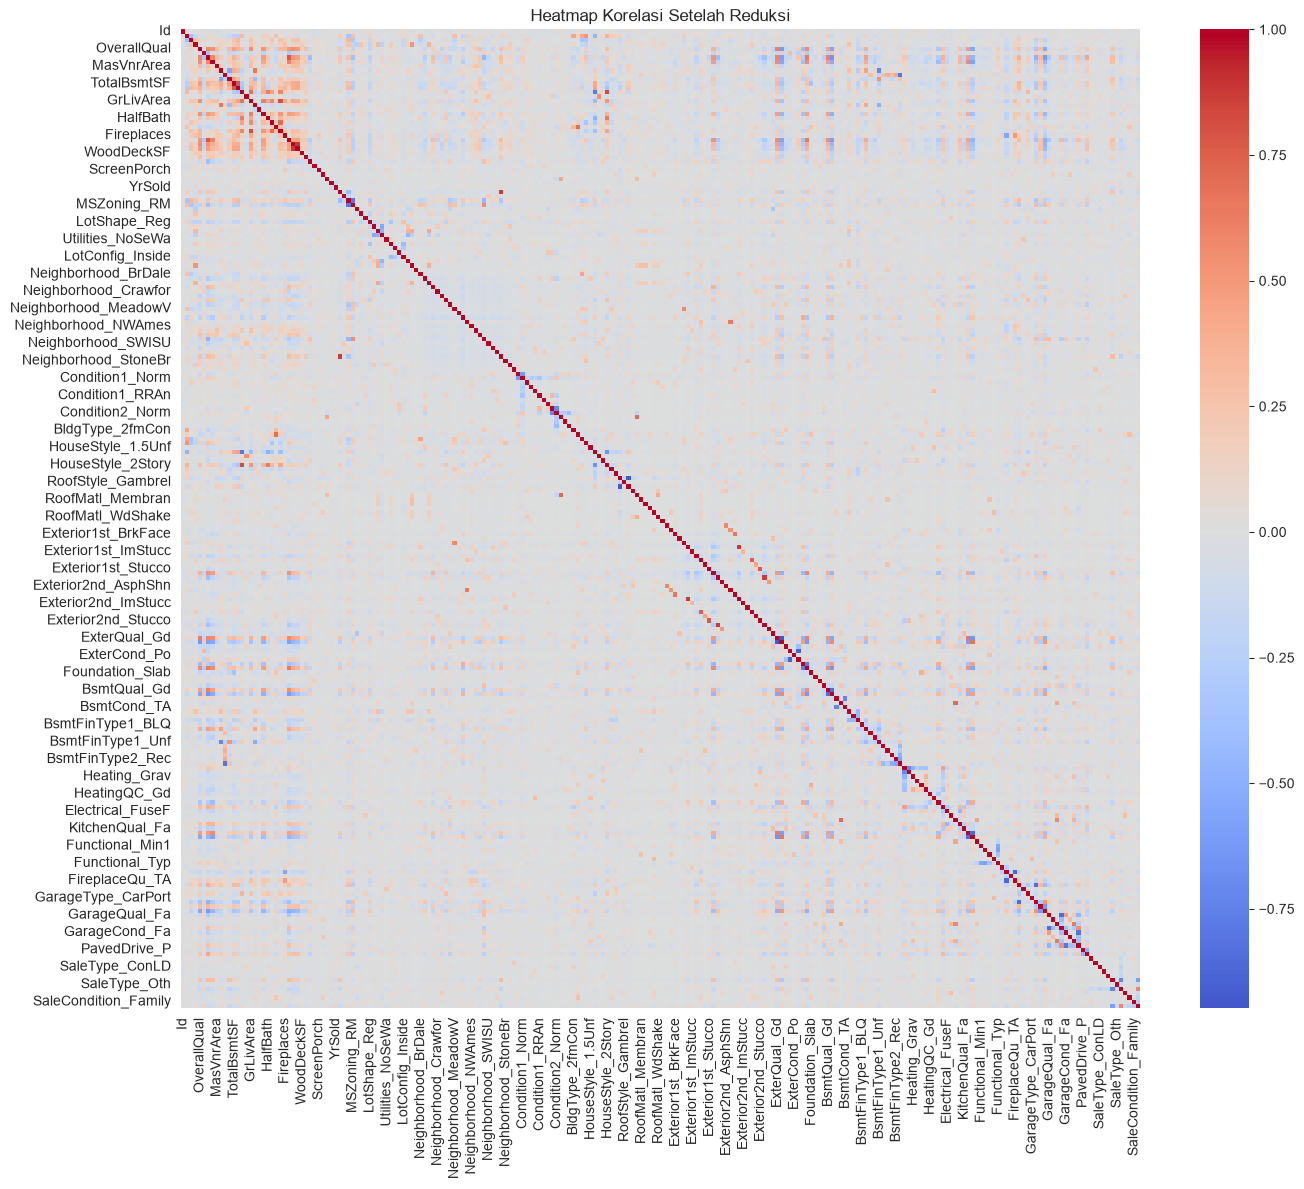

In [21]:
plt.figure(figsize=(14, 12))
sns.heatmap(X_reduced.corr(), cmap='coolwarm', center=0, cbar=True)
plt.title('Heatmap Korelasi Setelah Reduksi')
plt.tight_layout()
plt.show()

### 5.2 PCA (Principal Component Analysis)
PCA digunakan untuk mengurangi dimensi dengan mempertahankan **95% variansi** data.

In [22]:
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_reduced)

print("Shape setelah PCA:", X_pca.shape)
print("Jumlah komponen PCA:", pca.n_components_)
print("Total variansi dipertahankan: {:.2f}%".format(
    pca.explained_variance_ratio_.sum() * 100
))

Shape setelah PCA: (1378, 155)
Jumlah komponen PCA: 155
Total variansi dipertahankan: 95.06%


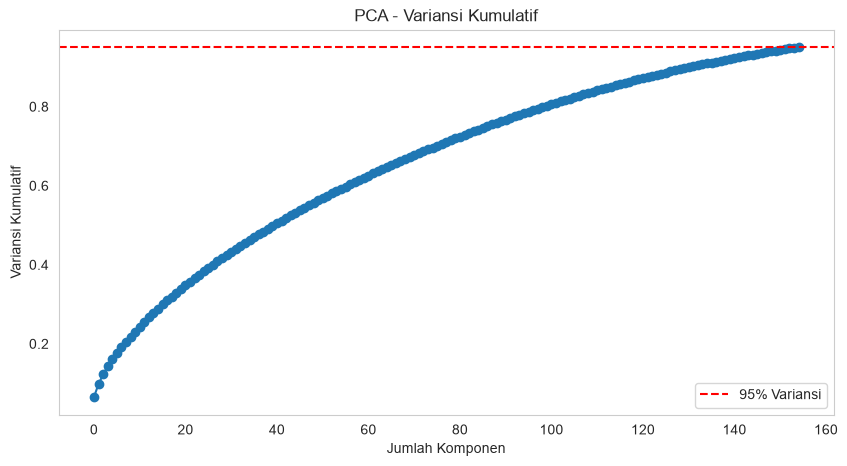

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.axhline(y=0.95, color='red', linestyle='--', label='95% Variansi')
plt.xlabel('Jumlah Komponen')
plt.ylabel('Variansi Kumulatif')
plt.title('PCA - Variansi Kumulatif')
plt.legend()
plt.grid()
plt.show()

## 6. Dataset Akhir

Dataset akhir terdiri dari komponen PCA + kolom target `SalePrice`.

In [24]:
final_df = pd.DataFrame(
    X_pca,
    columns=[f'PC{i+1}' for i in range(X_pca.shape[1])]
)
final_df['SalePrice'] = y.values

print("Shape dataset akhir:", final_df.shape)
final_df.head()

Shape dataset akhir: (1378, 156)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46,PC47,PC48,PC49,PC50,PC51,PC52,PC53,PC54,PC55,PC56,PC57,PC58,PC59,PC60,PC61,PC62,PC63,PC64,PC65,PC66,PC67,PC68,PC69,PC70,PC71,PC72,PC73,PC74,PC75,PC76,PC77,PC78,PC79,PC80,PC81,PC82,PC83,PC84,PC85,PC86,PC87,PC88,PC89,PC90,PC91,PC92,PC93,PC94,PC95,PC96,PC97,PC98,PC99,PC100,PC101,PC102,PC103,PC104,PC105,PC106,PC107,PC108,PC109,PC110,PC111,PC112,PC113,PC114,PC115,PC116,PC117,PC118,PC119,PC120,PC121,PC122,PC123,PC124,PC125,PC126,PC127,PC128,PC129,PC130,PC131,PC132,PC133,PC134,PC135,PC136,PC137,PC138,PC139,PC140,PC141,PC142,PC143,PC144,PC145,PC146,PC147,PC148,PC149,PC150,PC151,PC152,PC153,PC154,PC155,SalePrice
0,4.729328,-1.818016,-0.571665,-1.279910,0.312396,-0.074434,-0.424877,0.754992,-1.475747,-0.638400,-0.982743,-0.463832,0.798756,-0.616332,1.605413,-0.120195,-0.160806,-1.340439,-0.586296,0.404382,-0.373896,0.608085,0.304983,-1.731750,-0.134693,-0.417359,0.145284,0.429408,0.570317,0.210622,0.207839,-1.283299,0.001822,-0.011354,0.949850,-0.560248,-0.774448,0.804459,0.526061,0.827720,0.314124,-0.471986,-0.482296,0.077306,-0.499085,0.342131,-0.102637,0.453777,0.494476,0.077559,-0.122716,-0.152548,-0.679151,-0.690713,-0.325757,0.362391,0.404466,-0.301258,0.237329,0.304948,-0.391905,0.765159,-0.224541,0.171114,0.024179,-0.082272,-0.003127,-0.287204,-0.571868,-0.361563,-0.793612,-0.636901,0.127198,-0.153635,0.477309,-0.300776,-0.338914,0.381620,0.162777,0.200238,0.760483,0.122564,-0.452419,0.201989,0.331098,0.252402,-0.663780,0.010166,-0.691973,0.637562,0.014875,0.378283,0.390498,0.534313,-0.544643,0.146741,0.327465,0.242306,0.362619,-0.501862,-0.089087,-0.102709,0.153123,0.266452,0.434573,-0.352250,0.065436,-0.308779,0.636252,0.433025,0.153132,-0.055704,-0.464871,-0.512206,-0.234766,-0.234358,0.170428,0.056663,-0.301571,-0.130355,0.549841,0.368952,0.046434,0.058952,-0.158026,-0.081613,-0.226395,-0.407985,-0.495887,-0.197938,0.098642,-0.083082,0.206700,-0.111244,-0.084403,-0.333765,-0.094991,0.037744,-0.455213,-0.144188,0.379873,-0.226879,-0.200469,-0.337278,0.064264,-0.038337,0.094944,-0.255357,0.151642,0.145042,-0.316642,-0.394057,0.078609,-0.146227,-0.234464,208500.0
1,0.709448,3.626511,0.503609,-0.294164,0.889219,-0.426115,-0.222025,0.503705,0.713764,-1.019297,-2.224641,-0.576376,-1.506773,-1.015795,-0.765497,1.278233,1.796941,1.342940,0.767880,2.110586,0.163840,-2.933506,1.429099,1.008531,0.246115,-1.441721,0.249469,-0.290106,-0.635613,-2.576205,-1.163856,1.516501,-1.619843,0.647054,-0.608489,0.964647,-1.698515,-0.641891,-0.102303,0.476530,0.185768,-0.647292,4.812238,-0.353422,-2.738047,2.610253,2.716741,-0.721846,1.349280,-0.222594,0.560387,-0.466836,-0.994774,0.185563,-0.230398,-3.529948,-1.022386,0.671423,-0.230917,-0.248840,0.047162,-0.379875,3.180904,-1.721598,0.053282,-0.326183,1.064644,-0.521129,1.288894,-0.766219,-3.176613,0.417513,2.185019,-0.089927,1.393961,1.476718,-1.724006,-0.996171,-0.390457,-2.194142,0.396783,0.836460,-0.198869,-0.960998,0.043782,-1.409160,-1.443854,-0.630341,-0.735749,0.123199,0.060620,-0.361123,-0.314738,-1.282782,-1.755895,-0.732055,1.334375,-0.821310,-0.300363,-0.680569,1.086677,2.560148,-0.805669,-0.949566,0.235231,-1.301150,0.813615,2.039093,0.387298,0.246593,-2.665797,0.397230,0.336785,-1.461872,0.683112,1.088078,2.100971,-0.644532,1.930587,-1.568010,2.778820,-2.669620,-0.134345,-0.164364,-0.294630,-0.517170,-1.940076,-0.126865,-0.306048,0.053116,0.240620,-0.513183,-0.930701,-1.325876,1.266356,-0.972171,1.552773,0.051133,0.031473,-1.408578,-0.831736,0.988453,0.586096,0.480108,0.568827,1.331618,-0.800288,0.184661,-1.369821,0.258229,-0.098447,-0.089850,-0.095579,0.061855,0.195479,181500.0
2,5.480946,-0.935200,0.507271,-1.120214,1.236551,-0.607872,-0.449392,1.262925,-1.517170,-0.538591,-1.266685,-0.121700,0.063097,-0.341483,1.075756,-0.220517,0.382260,-1.195237,-0.064030,-0.16

In [25]:
final_df.to_csv('5054251017_RafaRizkiAiraSwala_Tugas_Praproses_Data.csv', index=False)
print("Dataset akhir berhasil disimpan sebagai 5054251017_RafaRizkiAiraSwala_Tugas_Praproses_Data.csv")

Dataset akhir berhasil disimpan sebagai 5054251017_RafaRizkiAiraSwala_Tugas_Praproses_Data.csv


## 7. Ringkasan

| Tahapan | Hasil |
|---------|-------|
| Dataset awal | 1460 baris × 81 kolom |
| Kolom dihapus (missing > 50%) | [isi otomatis] |
| Missing values | 0 (sudah diimputasi) |
| Outlier | Dihapus pada SalePrice & GrLivArea |
| Encoding | One-Hot Encoding |
| Standarisasi | StandardScaler |
| Reduksi korelasi | Kolom dengan korelasi > 0.95 dibuang |
| PCA | 95% variansi dipertahankan |

Dataset akhir siap digunakan untuk pemodelan machine learning.